# Validating the DC Motor Digital Twin

This notebook evaluates the trained RNN, LSTM, and GRU models on held-out simulated motor trajectories.

Unlike one-step prediction, multi-step rollout feeds each predicted current and speed back into the model. This tests whether prediction errors accumulate as the simulation progresses.

The reference is the MATLAB/Simulink motor model, not physical motor measurements.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow import keras
from tensorflow.keras import layers

## 1. Load the Dataset and Trained Models

This notebook uses the fixed-time dataset and the models and scalers saved by Notebook 2. Run Notebook 2 first if these files are missing or need to be regenerated.

In [35]:
dataset = pd.read_csv('../data/motor_dataset_fixed_time.csv')
dataset.head()

,Voltage,Load Torque,Time,Current,Speed
0,0.1,0.0,0.000,1.000000e-10,0.000000
1,0.1,0.0,0.001,2.564020e-02,0.043862
2,0.1,0.0,0.002,2.564018e-02,0.043910
3,0.1,0.0,0.003,2.564025e-02,0.044448
4,0.1,0.0,0.004,2.564019e-02,0.043912


In [36]:
rnn_model = keras.models.load_model('../models/rnn_model.keras')
lstm_model = keras.models.load_model('../models/lstm_model.keras')
gru_model = keras.models.load_model('../models/gru_model.keras')

input_scaler = joblib.load('../models/input_scaler.pkl')
output_scaler = joblib.load('../models/output_scaler.pkl')

## 2. Prepare the Held-Out Test Runs

The same run-level split is reconstructed using `random_state=42` so the evaluation uses the test runs reserved by Notebook 2.

Each run is converted into input-target sequences. The target represents current and speed one millisecond after the corresponding input.

In [37]:
dataset['Run'] = (dataset['Time'].diff()<0).cumsum()
run_ids = dataset['Run'].unique()
train_ids, test_ids = train_test_split(run_ids, test_size=0.2, random_state=42)
test_dataset = dataset[dataset['Run'].isin(test_ids)].copy()

In [38]:
test_dataset['Applied Torque'] = np.where(test_dataset['Time'] < 0.1, 0,test_dataset['Load Torque'])
# Define the features used by the model and the outputs it will predict
input_features = ['Voltage', 'Applied Torque', 'Current', 'Speed']
output_features = ['Current', 'Speed']

x_test = []
y_test = []

for run_id, run_data in test_dataset.groupby('Run'):
    run_data = run_data.sort_values('Time')
    current_inputs = run_data[input_features].iloc[:-1].values
    next_outputs = run_data[output_features].iloc[1:].values
    
    x_test.append(current_inputs)
    y_test.append(next_outputs)
    
x_test = np.array(x_test)
y_test = np.array(y_test)

In [39]:
x_test_scaled = input_scaler.transform(x_test.reshape(-1, x_test.shape[-1])).reshape(x_test.shape)
y_test_scaled = output_scaler.transform(y_test.reshape(-1, y_test.shape[-1])).reshape(y_test.shape)
y_test_original = output_scaler.inverse_transform(y_test_scaled.reshape(-1, 2)).reshape(y_test_scaled.shape)

## 3. Build Stateful Models for Rollout

The trained weights are copied into stateful versions of the three recurrent models. Their recurrent states are reset at the beginning of each run, then maintained between successive prediction steps.

In [40]:
def make_step_model(cell):
    m = keras.Sequential([
        keras.Input(batch_shape=(1, 1, 4)),
        cell(32, return_sequences=True, stateful=True),
        layers.Dense(2)])
    return m

def rollout(step_model, x_scaled_run, input_scaler, output_scaler):
    for layer in step_model.layers:
        if hasattr(layer, 'reset_state'):
            layer.reset_state()

    inp = x_scaled_run.copy()
    predictions = []

    for t in range(len(inp)):
        prediction = step_model(inp[t].reshape(1, 1, 4), training=False).numpy()[0, 0]
        predictions.append(prediction)
        if t < len(inp) - 1:
            # Convert predicted current and speed to their original units
            prediction_original = output_scaler.inverse_transform(prediction.reshape(1, 2))[0]
            # Recover the next input row in its original units
            next_input_original = input_scaler.inverse_transform(inp[t + 1].reshape(1, 4))[0]
            # Replace current and speed with the predictions
            next_input_original[2:] = prediction_original
            # Scale the complete row using the input scaler
            inp[t + 1] = input_scaler.transform(next_input_original.reshape(1, 4))[0]
    return np.array(predictions)

In [41]:
step_rnn = make_step_model(layers.SimpleRNN)
step_rnn.set_weights(rnn_model.get_weights())

step_lstm = make_step_model(layers.LSTM)
step_lstm.set_weights(lstm_model.get_weights())

step_gru = make_step_model(layers.GRU)
step_gru.set_weights(gru_model.get_weights())

In [42]:
rnn_predictions = []
lstm_predictions = []
gru_predictions = []

for run in range(len(x_test_scaled)):
    rnn_predictions.append(output_scaler.inverse_transform(rollout(step_rnn, x_test_scaled[run],input_scaler, output_scaler)))
    lstm_predictions.append(output_scaler.inverse_transform(rollout(step_lstm, x_test_scaled[run],input_scaler, output_scaler)))
    gru_predictions.append(output_scaler.inverse_transform(rollout(step_gru, x_test_scaled[run],input_scaler, output_scaler)))

rnn_predictions = np.array(rnn_predictions)
lstm_predictions = np.array(lstm_predictions)
gru_predictions = np.array(gru_predictions)

print('RNN:', rnn_predictions.shape)
print('LSTM:', lstm_predictions.shape)
print('GRU:', gru_predictions.shape)

RNN: (33, 200, 2)
LSTM: (33, 200, 2)
GRU: (33, 200, 2)


## 4. Evaluate Transient Behaviour

Errors are calculated over two time windows:

- **Startup:** target times up to 20 ms.
- **Load response:** target times after 100 ms and up to 120 ms, covering the period immediately after the load step.

These windows help distinguish initial motor acceleration from the response to applied load.

In [43]:
target_times = np.arange(1, 201) * 0.001 # 0..001s to 0.200s
startup_window = target_times <= 0.020
load_window = (target_times > 0.1) & (target_times <= 0.120)

predictions = {'RNN': rnn_predictions,
               'LSTM': lstm_predictions,
               'GRU': gru_predictions}

transient_results = []

for model_name, model_predictions in predictions.items():
    for window_name, window in [('Startup', startup_window),('Load Response', load_window)]:
        actual = y_test_original[:, window, :]
        predicted = model_predictions[:, window, :]

        transient_results.append({'Model': model_name, 'Window': window_name, 
                                  'Current MAE (A)': mean_absolute_error(actual[:, :, 0].ravel(), predicted[:, :, 0].ravel()),
                                  'Speed MAE (rpm)': mean_absolute_error(actual[:, :, 1].ravel(), predicted[:, :, 1].ravel()),
                                  'Current RMSE (A)': np.sqrt(mean_squared_error(actual[:, :, 0].ravel(), predicted[:, :, 0].ravel())),
                                  'Speed RMSE (rpm)': np.sqrt(mean_squared_error(actual[:, :, 1].ravel(), predicted[:, :, 1].ravel()))})
transient_results = pd.DataFrame(transient_results)
transient_results.round(5)

,Model,Window,Current MAE (A),Speed MAE (rpm),Current RMSE (A),Speed RMSE (rpm)
0,RNN,Startup,0.01630,752.65660,0.02098,914.63863
1,RNN,Load Response,0.03353,1693.00472,0.03847,1889.95283
2,LSTM,Startup,0.02100,803.83654,0.04274,1400.46887
3,LSTM,Load Response,0.00552,332.86262,0.00717,411.11717
4,GRU,Startup,0.01044,559.43731,0.02218,754.57903
5,GRU,Load Response,0.00568,456.87539,0.00681,550.74190


## 5. Evaluate Steady-State Behaviour

The final portion of each trajectory, after 180 ms, is used to estimate steady-state behaviour.

For each run, the predicted and reference values are averaged over this window. MAE and RMSE then measure errors in these per-run averages, while bias indicates whether the model tends to overpredict or underpredict.

In [44]:
steady_window = target_times > 0.180
steady_results = []

for model_name, model_predictions in predictions.items():
    actual_steady = y_test_original[:, steady_window, :].mean(axis = 1)
    predicted_steady = model_predictions[:, steady_window, :].mean(axis = 1)

    current_errors = predicted_steady[:, 0] - actual_steady[:, 0]
    speed_errors = predicted_steady[:, 1] - actual_steady[:, 1]

    steady_results.append({
        'Model': model_name,
        'Current MAE (A)': np.abs(current_errors).mean(),
        'Speed MAE (rpm)': np.abs(speed_errors).mean(),
        'Current RMSE (A)': np.sqrt(np.mean(current_errors**2)),
        'Speed RMSE (rpm)': np.sqrt(np.mean(speed_errors**2)),
        'Mean Current Bias (A)': current_errors.mean(),
        'Mean Speed Bias (rpm)': speed_errors.mean()
    })

steady_results = pd.DataFrame(steady_results)
steady_results.round(5)

,Model,Current MAE (A),Speed MAE (rpm),Current RMSE (A),Speed RMSE (rpm),Mean Current Bias (A),Mean Speed Bias (rpm)
0,RNN,0.03378,1686.84031,0.03783,1889.76642,0.01798,-854.11040
1,LSTM,0.00270,202.92492,0.00368,250.33206,-0.00083,79.00660
2,GRU,0.00799,532.84986,0.01091,699.60869,-0.00206,5.54756


## 6. Visual Comparison

The plot compares the three model rollouts with the Simulink reference for one held-out test run. It illustrates the transient and load response for that run; the metric tables above provide the broader evaluation across the test set.

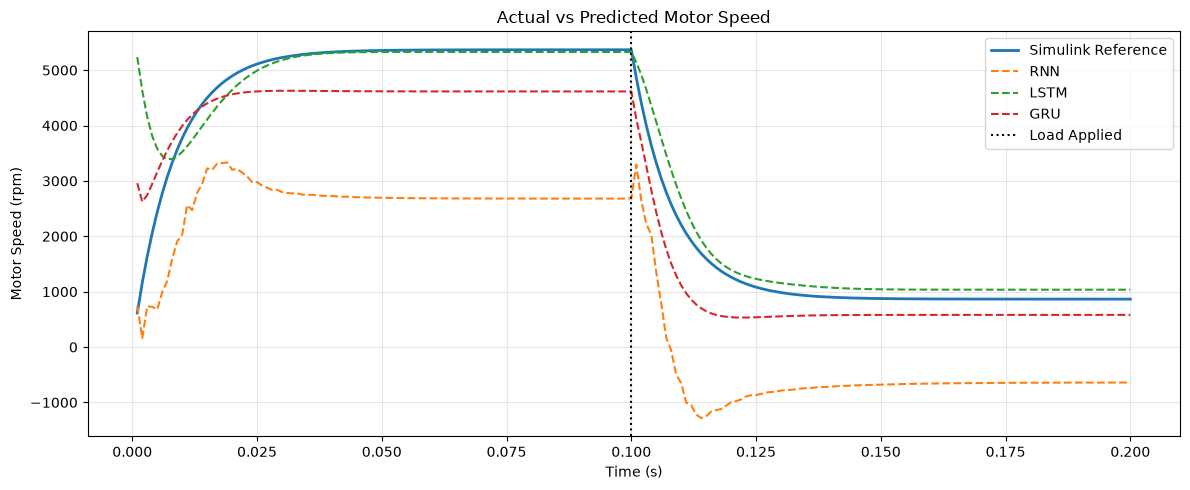

In [45]:
run_index = min(10, len(y_test_original) - 1)
actual_speed = y_test_original[run_index, :, 1]

plt.figure(figsize=(12, 5))
plt.plot(target_times, actual_speed, label='Simulink Reference', linewidth=2)
plt.plot(target_times, rnn_predictions[run_index, :, 1], label='RNN', linestyle='--')
plt.plot(target_times, lstm_predictions[run_index, :, 1], label='LSTM', linestyle='--')
plt.plot(target_times, gru_predictions[run_index, :, 1], label='GRU', linestyle='--')

plt.axvline(x=0.1, color='black', linestyle=':',label='Load Applied')
plt.xlabel('Time (s)')
plt.ylabel('Motor Speed (rpm)')
plt.title('Actual vs Predicted Motor Speed')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

## 7. Conclusion and Limitations

This notebook compares the transient and steady-state predictions of three recurrent models against a simulated DC motor reference.

The results describe agreement with the MATLAB/Simulink model under the simulated operating conditions. They do not establish accuracy on physical motor hardware.

The evaluation covers held-out operating points from the same simulation grid and the same startup and load-step profile. It therefore tests interpolation within these conditions rather than generalisation to arbitrary motor conditions.

Final conclusions about which recurrent model performs best should be based on the regenerated metrics after the rollout correction.